<a href="https://colab.research.google.com/github/aytug-guler/GROUP19_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CENG313 - Assignment 1: EDA and Baseline Models

**Competition:** MABe Challenge - Social Action Recognition in Mice

**Group:** GROUP19 (Medium)

**Members:** Efe Zeybek, Aytuğ Güler

## Objective
This notebook explores the MABe mouse behavior dataset, analyzes its structure and distributions, and develops baseline models for social behavior recognition.


In [1]:

%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn pyarrow


In [2]:

import os
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Environment setup completed successfully!")
print("Pandas version:", pd.__version__)


Environment setup completed successfully!
Pandas version: 2.2.3


In [6]:

data_dir = Path(
    kagglehub.competition_download(
        "MABe-mouse-behavior-detection"
    )
)

print("Dataset directory:", data_dir)
print("\nFiles and folders:")

for item in data_dir.iterdir():
    print("-", item.name)


100%|██████████| 2.63G/2.63G [00:37<00:00, 74.6MB/s]

Extracting files...


Dataset directory: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection

Files and folders:
- train_tracking
- train_annotation
- test.csv
- sample_submission.csv
- test_tracking
- train.csv


## 1. Exploratory Data Analysis (EDA)

In this section, we explore the structure, metadata, and characteristics of the MABe dataset before developing baseline models.

In [7]:

# Load training and test metadata

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nFirst five training records:")
display(train.head())

print("\nFirst five test records:")
display(test.head())


Training dataset shape: (8789, 38)
Test dataset shape: (1, 38)

Training columns:
['lab_id', 'video_id', 'mouse1_strain', 'mouse1_color', 'mouse1_sex', 'mouse1_id', 'mouse1_age', 'mouse1_condition', 'mouse2_strain', 'mouse2_color', 'mouse2_sex', 'mouse2_id', 'mouse2_age', 'mouse2_condition', 'mouse3_strain', 'mouse3_color', 'mouse3_sex', 'mouse3_id', 'mouse3_age', 'mouse3_condition', 'mouse4_strain', 'mouse4_color', 'mouse4_sex', 'mouse4_id', 'mouse4_age', 'mouse4_condition', 'frames_per_second', 'video_duration_sec', 'pix_per_cm_approx', 'video_width_pix', 'video_height_pix', 'arena_width_cm', 'arena_height_cm', 'arena_shape', 'arena_type', 'body_parts_tracked', 'behaviors_labeled', 'tracking_method']

First five training records:


,lab_id,video_id,mouse1_strain,mouse1_color,mouse1_sex,mouse1_id,mouse1_age,mouse1_condition,mouse2_strain,mouse2_color,...,pix_per_cm_approx,video_width_pix,video_height_pix,arena_width_cm,arena_height_cm,arena_shape,arena_type,body_parts_tracked,behaviors_labeled,tracking_method
0,AdaptableSnail,44566106,CD-1 (ICR),white,male,10.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1228,1068,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
1,AdaptableSnail,143861384,CD-1 (ICR),white,male,3.0,8-12 weeks,NaN,CD-1 (ICR),white,...,9.7,968,608,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
2,AdaptableSnail,209576908,CD-1 (ICR),white,male,7.0,8-12 weeks,NaN,CD-1 (ICR),white,...,16.0,1266,1100,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
3,AdaptableSnail,278643799,CD-1 (ICR),white,male,11.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1224,1100,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
4,AdaptableSnail,351967631,CD-1 (ICR),white,male,14.0,8-12 weeks,NaN,CD-1 (ICR),white,...,16.0,1204,1068,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut



First five test records:


,lab_id,video_id,mouse1_strain,mouse1_color,mouse1_sex,mouse1_id,mouse1_age,mouse1_condition,mouse2_strain,mouse2_color,...,pix_per_cm_approx,video_width_pix,video_height_pix,arena_width_cm,arena_height_cm,arena_shape,arena_type,body_parts_tracked,behaviors_labeled,tracking_method
0,AdaptableSnail,438887472,CD-1 (ICR),white,male,13.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1214,1090,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut


In [8]:

# Inspect tracking and annotation files

tracking_files = sorted(
    (data_dir / "train_tracking").rglob("*.parquet")
)

annotation_files = sorted(
    (data_dir / "train_annotation").rglob("*.parquet")
)

test_tracking_files = sorted(
    (data_dir / "test_tracking").rglob("*.parquet")
)

print("Training tracking files:", len(tracking_files))
print("Training annotation files:", len(annotation_files))
print("Test tracking files:", len(test_tracking_files))

if tracking_files:
    print("\nExample tracking file:")
    print(tracking_files[0])

if annotation_files:
    print("\nExample annotation file:")
    print(annotation_files[0])


Training tracking files: 8789
Training annotation files: 847
Test tracking files: 1

Example tracking file:
/root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_tracking/AdaptableSnail/1212811043.parquet

Example annotation file:
/root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_annotation/AdaptableSnail/1212811043.parquet


### 1.1 Dataset Overview and Data Quality

We analyze the training metadata to understand the dataset structure, missing values, laboratory distributions, and video characteristics.

In [9]:

# Dataset overview and basic statistics

print("Training videos:", len(train))
print("Test videos:", len(test))
print("Number of columns:", train.shape[1])

print("\nColumn data types:")
display(train.dtypes.to_frame("Data type"))

print("\nNumeric summary:")
display(train.describe().T)

print("\nNumber of laboratories:", train["lab_id"].nunique())

print("\nLaboratory distribution:")
display(train["lab_id"].value_counts())


Training videos: 8789
Test videos: 1
Number of columns: 38

Column data types:


,Data type
lab_id,object
video_id,int64
mouse1_strain,object
mouse1_color,object
mouse1_sex,object
mouse1_id,float64
mouse1_age,object
mouse1_condition,object
mouse2_strain,object
mouse2_color,object



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
video_id,8789.0,1.072697e+09,6.209820e+08,9603.0,5.380940e+08,1.072003e+09,1.615401e+09,2.147479e+09
mouse1_id,816.0,2.457108e+01,2.244420e+01,1.0,6.000000e+00,1.500000e+01,3.800000e+01,8.000000e+01
mouse2_id,108.0,1.951852e+01,1.166069e+01,1.0,1.200000e+01,1.700000e+01,2.425000e+01,5.300000e+01
mouse3_id,17.0,3.558824e+01,4.542285e+00,29.0,3.200000e+01,3.500000e+01,3.900000e+01,4.200000e+01
mouse4_id,10.0,4.840000e+01,2.951459e+00,44.0,4.625000e+01,4.800000e+01,5.100000e+01,5.200000e+01
frames_per_second,8789.0,3.040265e+01,6.434061e+00,10.0,3.000000e+01,3.000000e+01,3.000000e+01,1.200200e+02
video_duration_sec,8789.0,1.346479e+02,6.371238e+02,19.0,6.000000e+01,6.000000e+01,6.000000e+01,1.980100e+04
pix_per_cm_approx,8789.0,1.244019e+01,3.405194e+00,5.5,1.170000e+01,1.170000e+01,1.170000e+01,6.500000e+01
video_width_pix,8789.0,8.136542e+02,1.094109e+02,300.0,8.000000e+02,8.000000e+02,8.000000e+02,2.048000e+03
video_height_pix,8789.0,7.903697e+02,1.338698e+02,194.0,8.000000e+02,8.000000e+02,8.000000e+02,2.056000e+03



Number of laboratories: 21

Laboratory distribution:


,count
lab_id,
MABe22_keypoints,5320
MABe22_movies,2606
CalMS21_supplemental,297
CalMS21_task1,101
CalMS21_task2,76
SparklingTapir,69
JovialSwallow,52
PleasantMeerkat,36
InvincibleJellyfish,33


,Missing Count,Missing Percentage
mouse4_condition,8786,99.965866
mouse4_color,8779,99.886221
mouse4_strain,8779,99.886221
mouse4_sex,8779,99.886221
mouse4_id,8779,99.886221
mouse4_age,8778,99.874844
mouse3_id,8772,99.806576
mouse2_id,8681,98.771191
mouse1_id,7973,90.715667
behaviors_labeled,7941,90.351576


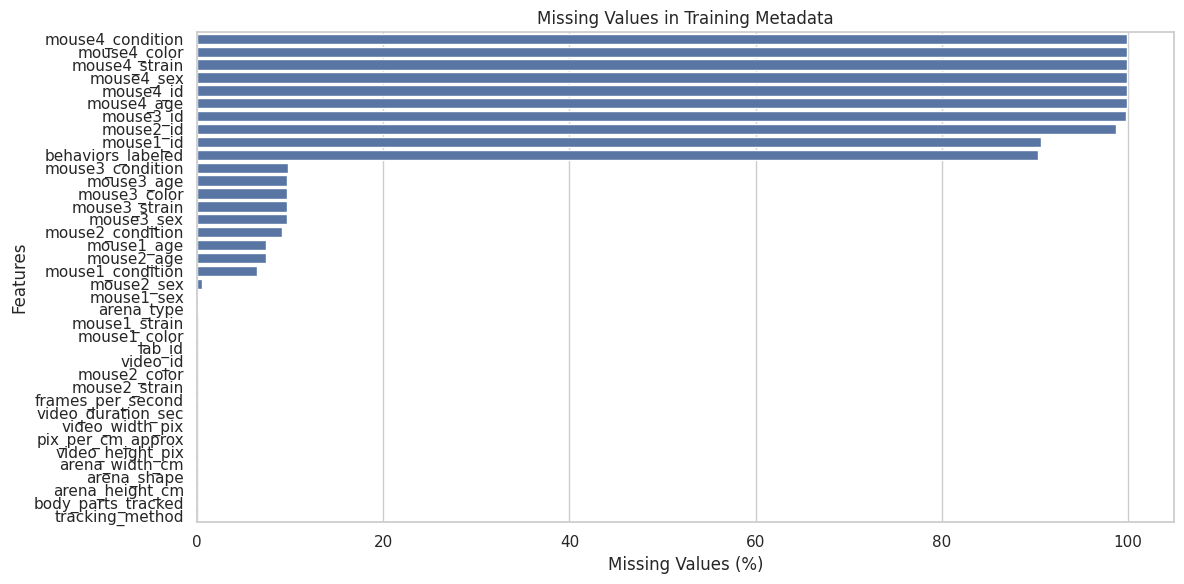

In [10]:

# Missing values analysis

missing_count = train.isnull().sum()

missing_percentage = (
    train.isnull().mean() * 100
)

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
}).sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_df.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title("Missing Values in Training Metadata")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


### Missing Values – Findings

The dataset contains substantial missing values in mouse identification fields and behavior annotation metadata. For example, `mouse1_id` is missing in approximately 90.72% of the training records, while `behaviors_labeled` is missing in approximately 90.35%.

However, important numerical metadata such as frame rate, video duration, and arena dimensions are complete. Missing metadata values should not automatically be replaced with zero, since some fields may be unavailable or not applicable to certain recordings.

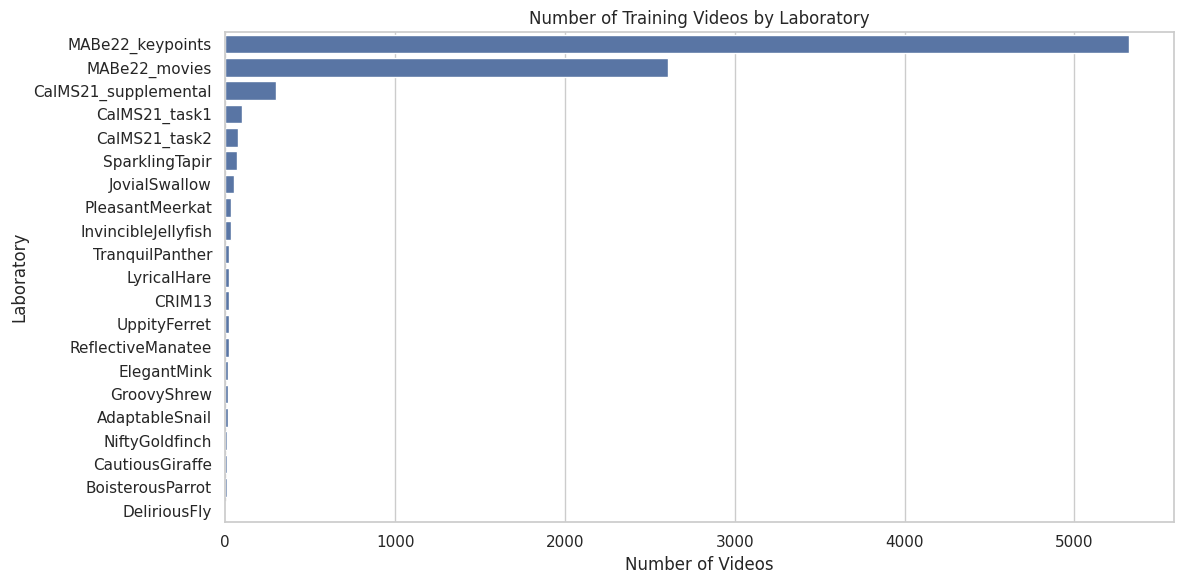

Total laboratories: 21
Largest laboratory: MABe22_keypoints
Videos in largest laboratory: 5320


In [11]:

# Laboratory distribution

lab_counts = train["lab_id"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=lab_counts.values,
    y=lab_counts.index
)

plt.title("Number of Training Videos by Laboratory")
plt.xlabel("Number of Videos")
plt.ylabel("Laboratory")
plt.tight_layout()
plt.show()

print("Total laboratories:", len(lab_counts))
print("Largest laboratory:", lab_counts.index[0])
print("Videos in largest laboratory:", lab_counts.iloc[0])


### Laboratory Distribution – Findings

The training dataset contains videos from 21 laboratories. However, the distribution is highly imbalanced. MABe22_keypoints contributes 5,320 videos (60.5%), while MABe22_movies contributes 2,606 videos (29.7%). Together, these two sources account for approximately 90.2% of the training videos.

This imbalance should be considered when selecting training and validation data, as a model trained predominantly on these sources may not generalize well to smaller laboratories.

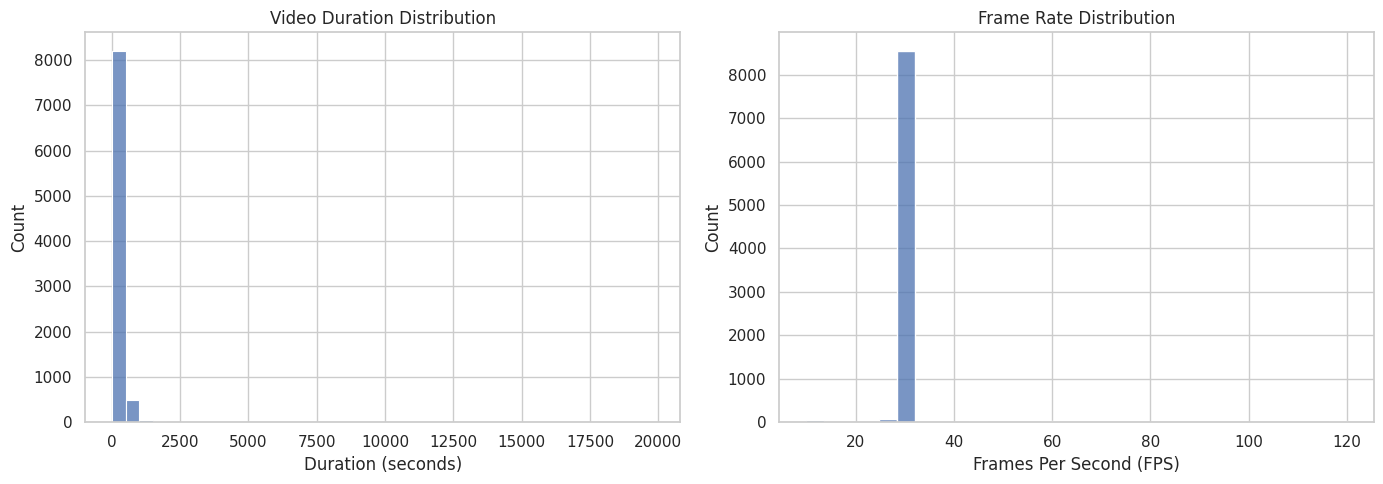

Average duration: 134.6478552736375
Average FPS: 30.402647627716462


In [12]:

# Video duration and frame rate distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train,
    x="video_duration_sec",
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Video Duration Distribution")
axes[0].set_xlabel("Duration (seconds)")

sns.histplot(
    data=train,
    x="frames_per_second",
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Frame Rate Distribution")
axes[1].set_xlabel("Frames Per Second (FPS)")

plt.tight_layout()
plt.show()

print("Average duration:", train["video_duration_sec"].mean())
print("Average FPS:", train["frames_per_second"].mean())


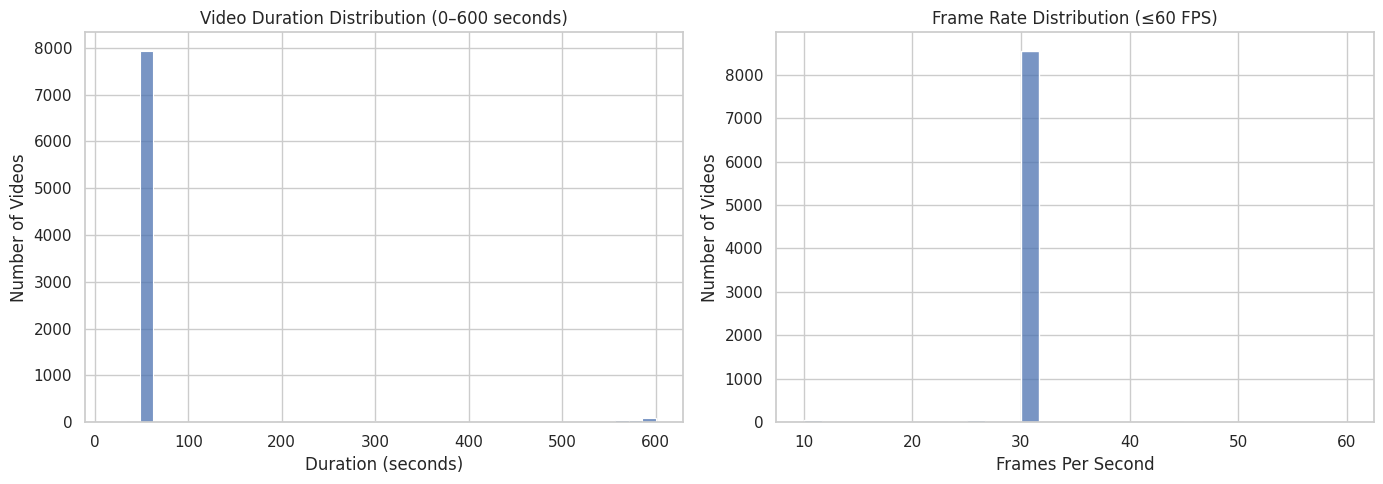

Videos longer than 600 seconds: 404
Videos above 60 FPS: 43


In [13]:

# Improved video duration and FPS distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Focus on typical video durations
sns.histplot(
    train.loc[
        train["video_duration_sec"] <= 600,
        "video_duration_sec"
    ],
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Video Duration Distribution (0–600 seconds)")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of Videos")

# Focus on common frame rates
sns.histplot(
    train.loc[
        train["frames_per_second"] <= 60,
        "frames_per_second"
    ],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Frame Rate Distribution (≤60 FPS)")
axes[1].set_xlabel("Frames Per Second")
axes[1].set_ylabel("Number of Videos")

plt.tight_layout()
plt.show()

print(
    "Videos longer than 600 seconds:",
    (train["video_duration_sec"] > 600).sum()
)

print(
    "Videos above 60 FPS:",
    (train["frames_per_second"] > 60).sum()
)


### Video Duration and Frame Rate – Findings

The average video duration is approximately 134.65 seconds, while the median duration is 60 seconds. The dataset includes 404 videos longer than 600 seconds, indicating substantial variation in recording length.

The average frame rate is approximately 30.40 FPS, with a median of 30 FPS. Only 43 videos have frame rates above 60 FPS.

These differences are relevant for feature extraction and computational efficiency. Motion-related features should account for frame rate differences to ensure comparability across recordings.

### 1.2 Tracking and Behavior Annotation Analysis

This section examines mouse tracking coordinates and annotated behavior intervals to understand the structure of the prediction task.

In [14]:

# Inspect one labeled video and its tracking data

annotation_path = annotation_files[0]

tracking_path = (
    data_dir
    / "train_tracking"
    / annotation_path.parent.name
    / annotation_path.name
)

annotation_example = pd.read_parquet(annotation_path)
tracking_example = pd.read_parquet(tracking_path)

print("ANNOTATION DATA")
print("File:", annotation_path)
print("Shape:", annotation_example.shape)
print("Columns:", annotation_example.columns.tolist())

display(annotation_example.head(10))

print("\nTRACKING DATA")
print("File:", tracking_path)
print("Shape:", tracking_example.shape)
print("Columns:", tracking_example.columns.tolist())

display(tracking_example.head(10))


ANNOTATION DATA
File: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_annotation/AdaptableSnail/1212811043.parquet
Shape: (370, 5)
Columns: ['agent_id', 'target_id', 'action', 'start_frame', 'stop_frame']


,agent_id,target_id,action,start_frame,stop_frame
0,1,3,chase,2,54
1,1,3,chase,128,234
2,3,2,avoid,324,342
3,3,1,avoid,324,342
4,1,2,chase,942,1052
5,4,3,chase,1205,1276
6,4,3,chase,1313,1370
7,1,2,chase,1416,1458
8,4,3,chase,1819,1908
9,4,2,chase,2041,2101



TRACKING DATA
File: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_tracking/AdaptableSnail/1212811043.parquet
Shape: (2677006, 5)
Columns: ['video_frame', 'mouse_id', 'bodypart', 'x', 'y']


,video_frame,mouse_id,bodypart,x,y
0,0,1,body_center,496.187012,376.475006
1,0,1,ear_left,494.059998,343.924011
2,0,1,ear_right,518.765015,367.362000
3,0,1,lateral_left,474.536987,370.563995
4,0,1,lateral_right,505.825012,394.937012
5,0,1,nose,527.765015,342.686005
6,0,1,tail_base,477.536011,398.338013
7,0,1,tail_midpoint,446.834015,429.035004
8,0,1,tail_tip,424.618011,457.161011
9,0,2,body_center,702.916016,322.872986


### 1.3 Behavior Annotation Distribution

We analyze the frequency and duration of annotated behavior events across the training dataset to identify class imbalance and inform baseline model selection.

In [15]:

# Aggregate behavior annotations across all labeled videos

from collections import Counter

action_counts = Counter()
action_durations = Counter()
annotated_video_counts = Counter()

total_events = 0

for path in annotation_files:
    df = pd.read_parquet(
        path,
        columns=["action", "start_frame", "stop_frame"]
    )

    # Count annotated behavior events
    counts = df["action"].value_counts()
    action_counts.update(counts.to_dict())

    # Count annotated frames per behavior event
    durations = (
        df["stop_frame"] - df["start_frame"]
    )

    duration_by_action = durations.groupby(
        df["action"]
    ).sum()

    action_durations.update(duration_by_action.to_dict())

    # Number of videos containing each action
    annotated_video_counts.update(
        df["action"].dropna().unique()
    )

    total_events += len(df)

behavior_summary = pd.DataFrame({
    "Action": list(action_counts.keys()),
    "Event Count": [
        action_counts[a] for a in action_counts
    ],
    "Annotated Frames": [
        action_durations[a] for a in action_counts
    ],
    "Videos": [
        annotated_video_counts[a] for a in action_counts
    ]
}).sort_values(
    "Event Count",
    ascending=False
).reset_index(drop=True)

print("Annotation files:", len(annotation_files))
print("Total annotated events:", total_events)
print("Unique behaviors:", len(action_counts))

display(behavior_summary.head(30))


Annotation files: 847
Total annotated events: 83620
Unique behaviors: 37


,Action,Event Count,Annotated Frames,Videos
0,sniff,37837,2150590,594
1,sniffgenital,7862,703931,405
2,attack,7462,518870,332
3,rear,4408,230889,85
4,sniffbody,3518,103274,109
5,approach,3270,85968,159
6,sniffface,2811,71527,108
7,mount,2747,284931,247
8,escape,2071,90304,93
9,reciprocalsniff,1492,40682,21


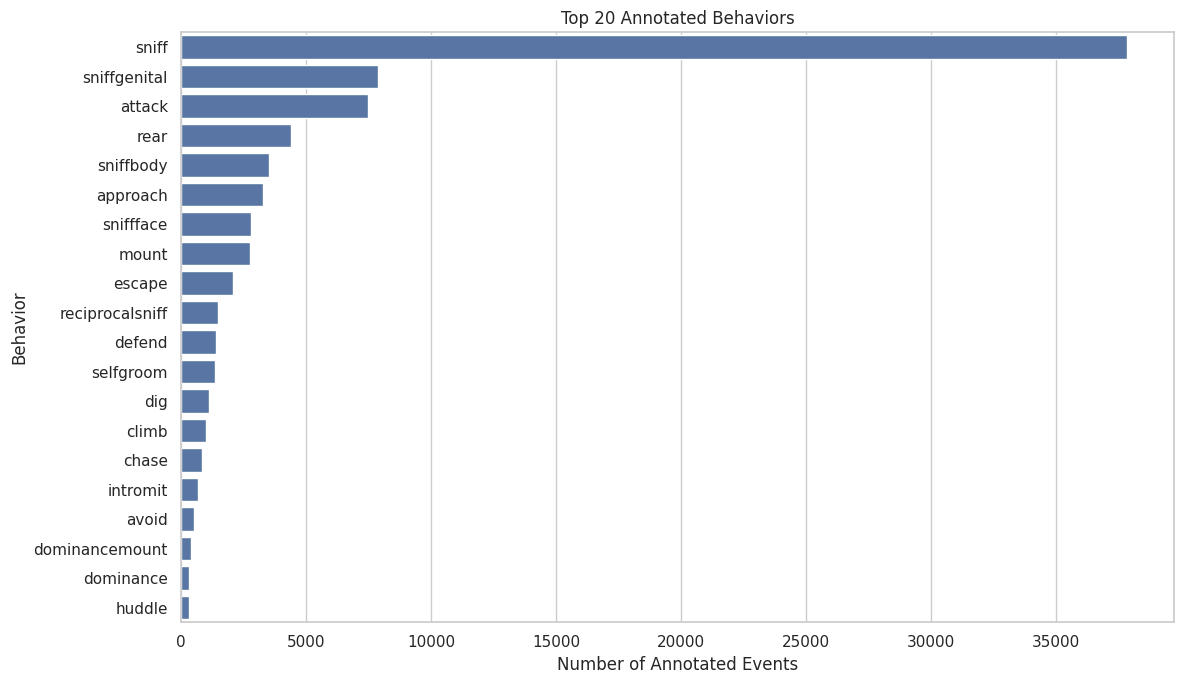

In [16]:

# Visualize the most frequent behaviors

top_actions = behavior_summary.head(20)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_actions,
    x="Event Count",
    y="Action"
)

plt.title("Top 20 Annotated Behaviors")
plt.xlabel("Number of Annotated Events")
plt.ylabel("Behavior")

plt.tight_layout()
plt.show()


### Behavior Distribution – Findings

The training annotation data contains 83,620 labeled behavior events across 847 annotation files, representing 37 distinct behavior categories.

The most frequent behavior is `sniff`, with 37,837 events, accounting for approximately 45.2% of all annotated events. Other frequently observed behaviors include `sniffgenital`, `attack`, and `rear`.

This distribution reveals substantial class imbalance. Therefore, baseline models should be evaluated using appropriate metrics, such as precision, recall, and F1-score, rather than relying on accuracy alone.

Additionally, behavior annotation coverage varies across videos and laboratories, which must be considered when constructing training and validation datasets.
